# 03 - Baseline Experiment Analysis

**Single-image ResNet-18 baseline, shared protocol**

The baseline is the only baseline used in any comparison. It was trained by the
same training loop, with the same checkpoint-selection rule and the same metric
implementation as the proposed model, and it was evaluated on the standard test
partition by the same evaluation code.

| Input | Partition | Produced by |
|---|---|---|
| `metrics.csv` | validation | training loop |
| `metrics.json`, `per_class.csv`, `confusion_matrix.npy` | standard test | shared evaluation entry point |

Nothing in this notebook selects a model or tunes a threshold. The checkpoint was
selected during training, before the test partition was read, and it is reproduced
here only to make the selection rule visible.

> Run the training and evaluation steps for this arm before executing the notebook.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

# The project's metrics module selects a non-interactive backend when it is
# imported, so that headless scripts can use it. Import it first, then re-enable
# the inline backend so that figures render in the notebook.
from src.evaluation.metrics import is_better_checkpoint

%matplotlib inline

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.metrics import classification_report

RUN_PARENT = ROOT / 'runs/baseline_resnet18_trainer'
RUN_DIR = sorted(p for p in RUN_PARENT.iterdir() if p.is_dir())[-1]
EVAL_DIR = ROOT / 'results/experiment_1_standard/baseline'

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200)

print('run directory :', RUN_DIR.relative_to(ROOT))
print('eval directory:', EVAL_DIR.relative_to(ROOT))

run directory : runs\baseline_resnet18_trainer\20261121T162957Z
eval directory: results\experiment_1_standard\baseline


## 1. Training and validation curves

Loss, accuracy, macro F1, and minimum class accuracy against epoch, over the arm's
full budget. The shaded background marks the recorded training stages: the backbone
is frozen in the first stage and unfrozen in the second.

Training accuracy is not recorded by the training loop, so the accuracy panel shows
the validation curve only. Accuracy is plotted for completeness. It is not the
selection criterion, and the last two panels are what the selection rule reads.

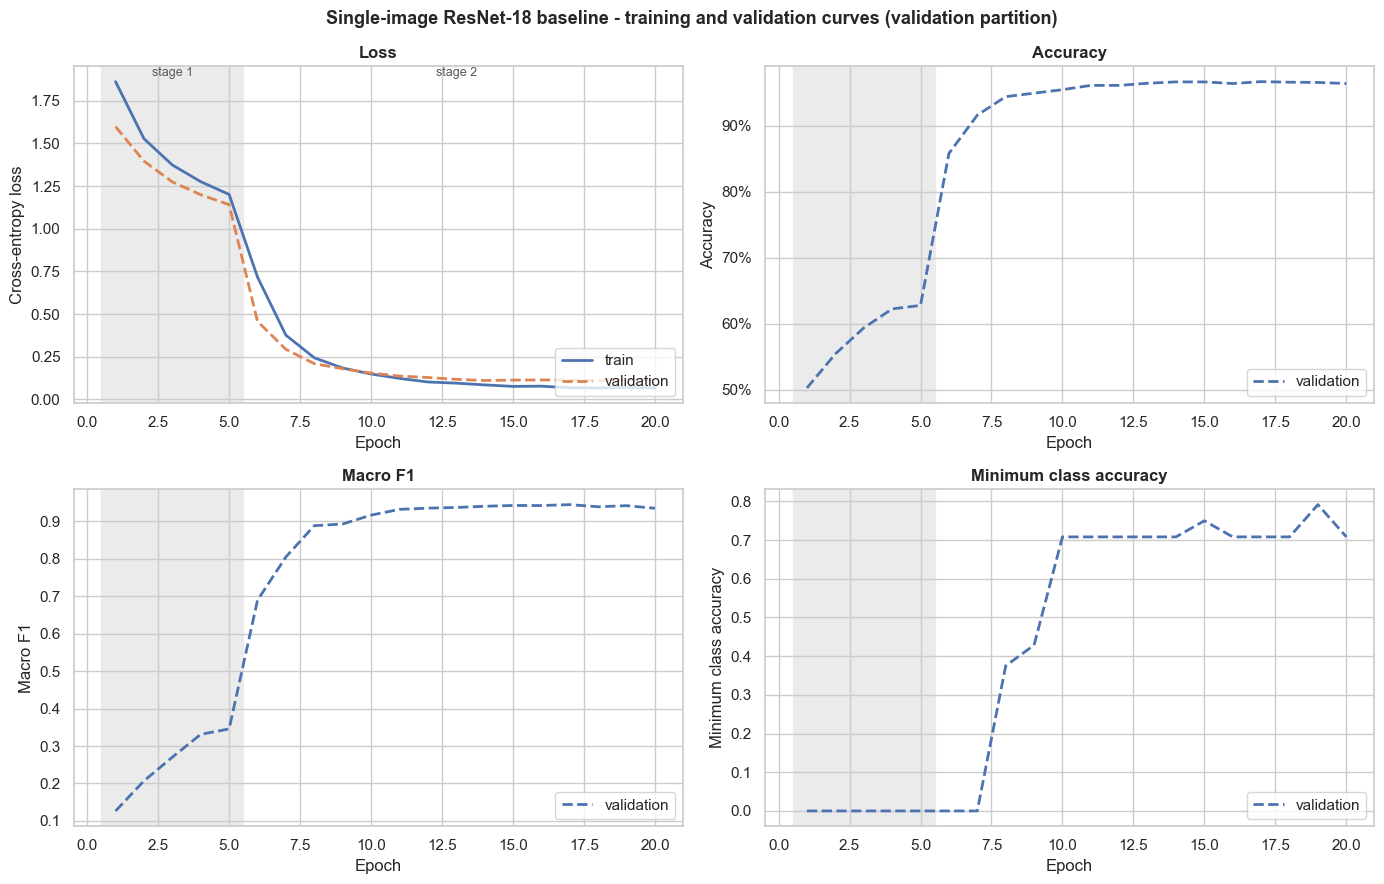

,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_min_class_accuracy
14,15,0.0762,0.1131,0.9663,0.9425,0.7500
15,16,0.0774,0.1140,0.9639,0.9424,0.7083
16,17,0.0678,0.1130,0.9667,0.9448,0.7083
17,18,0.0670,0.1100,0.9659,0.9391,0.7083
18,19,0.0704,0.1167,0.9655,0.9420,0.7917
19,20,0.0674,0.1144,0.9639,0.9350,0.7083


In [2]:
metrics = pd.read_csv(RUN_DIR / 'metrics.csv').sort_values('epoch').reset_index(drop=True)
cfg = yaml.safe_load((RUN_DIR / 'config.yaml').read_text(encoding='utf-8'))

stages = sorted(
    cfg['training']['phases'].items(),
    key=lambda item: item[1]['epochs'][0],
)
stage_spans = [
    (info['epochs'][0], min(info['epochs'][1], int(metrics['epoch'].max())))
    for _, info in stages
]
stage_spans = [span for span in stage_spans if span[0] <= span[1]]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [
    ('train_loss', 'val_loss', 'Loss', 'Cross-entropy loss', None),
    (None, 'val_accuracy', 'Accuracy', 'Accuracy', 'percent'),
    (None, 'val_macro_f1', 'Macro F1', 'Macro F1', None),
    (None, 'val_min_class_accuracy', 'Minimum class accuracy', 'Minimum class accuracy', None),
]

for ax, (train_col, val_col, title_text, ylabel, fmt) in zip(axes.ravel(), panels):
    for k, (start, end) in enumerate(stage_spans):
        if k % 2 == 0:
            ax.axvspan(start - 0.5, end + 0.5, color='0.92', zorder=0)
    if train_col is not None:
        ax.plot(metrics['epoch'], metrics[train_col], label='train', linewidth=2)
    if val_col in metrics.columns:
        ax.plot(metrics['epoch'], metrics[val_col], label='validation',
                linewidth=2, linestyle='--')
    ax.set_title(title_text, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    if fmt == 'percent':
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc='lower right')

for k, (start, end) in enumerate(stage_spans):
    axes[0, 0].text(
        (start + end) / 2, axes[0, 0].get_ylim()[1],
        f'stage {k + 1}', ha='center', va='top', fontsize=9, color='0.35',
    )

fig.suptitle(
    'Single-image ResNet-18 baseline - training and validation curves (validation partition)',
    fontsize=13, fontweight='bold',
)
plt.tight_layout()
plt.savefig(EVAL_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

metrics[[
    'epoch', 'train_loss', 'val_loss', 'val_accuracy',
    'val_macro_f1', 'val_min_class_accuracy',
]].tail(6).round(4)

## 2. Checkpoint analysis

The checkpoint was selected by validation macro F1, with a 0.005 tie window that is
broken by minimum class accuracy. The rule is applied epoch by epoch against the
best value seen so far, so a later epoch can displace an earlier one even when its
macro F1 is slightly lower.

The simulation below calls the trainer's own implementation of that comparison, so
the epoch it returns is the epoch the trainer saved.

The interesting case is a run where the highest macro F1 and the selected checkpoint
are different epochs. The plot shows why the rule chose what it chose.

In [3]:
best_f1 = best_min_acc = None
selected_epoch = None

for _, row in metrics.iterrows():
    if is_better_checkpoint(
        row['val_macro_f1'], row['val_min_class_accuracy'], best_f1, best_min_acc
    ):
        best_f1 = float(row['val_macro_f1'])
        best_min_acc = float(row['val_min_class_accuracy'])
        selected_epoch = int(row['epoch'])

selected = metrics.loc[metrics['epoch'] == selected_epoch].iloc[0]
peak = metrics.loc[metrics['val_macro_f1'].idxmax()]

print(f'selected epoch      : {selected_epoch}')
print(f'macro F1            : {selected["val_macro_f1"]:.6f}')
print(f'minimum class acc.  : {selected["val_min_class_accuracy"]:.6f}')
print(f'peak macro F1 epoch : {int(peak["epoch"])} ({peak["val_macro_f1"]:.6f})')

window = metrics[
    metrics['val_macro_f1'] >= peak['val_macro_f1'] - 0.005
][['epoch', 'val_macro_f1', 'val_min_class_accuracy']]
print('\nepochs inside the 0.005 window of the peak macro F1:')
window.round(6)

selected epoch      : 19
macro F1            : 0.942009
minimum class acc.  : 0.791667
peak macro F1 epoch : 17 (0.944755)

epochs inside the 0.005 window of the peak macro F1:


,epoch,val_macro_f1,val_min_class_accuracy
13,14,0.940430,0.708333
14,15,0.942546,0.750000
15,16,0.942375,0.708333
16,17,0.944755,0.708333
18,19,0.942009,0.791667


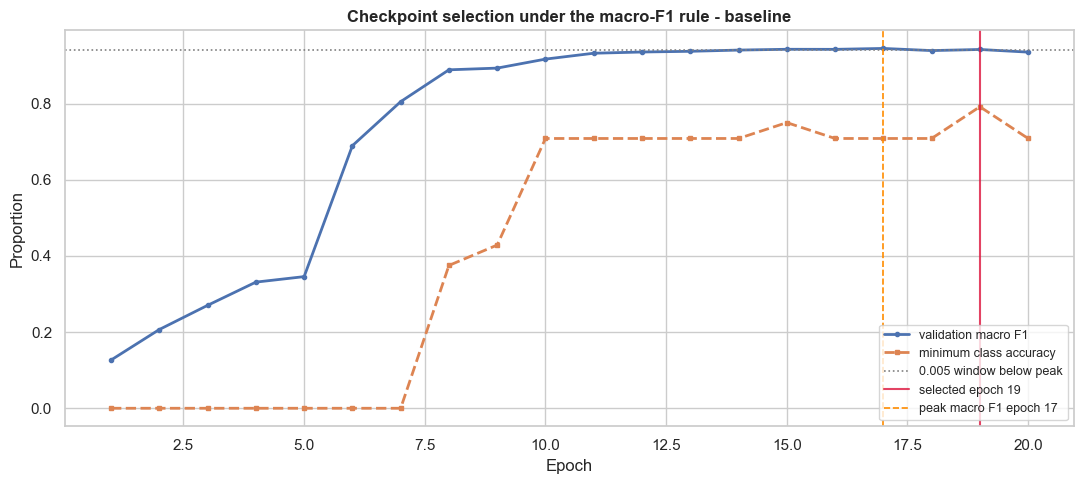

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(metrics['epoch'], metrics['val_macro_f1'], marker='o', markersize=3,
        linewidth=2, label='validation macro F1')
ax.plot(metrics['epoch'], metrics['val_min_class_accuracy'], marker='s', markersize=3,
        linewidth=2, linestyle='--', label='minimum class accuracy')

ax.axhline(peak['val_macro_f1'] - 0.005, color='0.5', linestyle=':', linewidth=1.2,
           label='0.005 window below peak')
ax.axvline(selected_epoch, color='crimson', linewidth=1.5, alpha=0.8,
           label=f'selected epoch {selected_epoch}')

if int(peak['epoch']) != selected_epoch:
    ax.axvline(int(peak['epoch']), color='darkorange', linestyle='--', linewidth=1.2,
               label=f'peak macro F1 epoch {int(peak["epoch"])}')

ax.set_xlabel('Epoch')
ax.set_ylabel('Proportion')
ax.set_title('Checkpoint selection under the macro-F1 rule - baseline', fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(EVAL_DIR / 'checkpoint_selection.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Validation performance summary

The selected checkpoint, read from the validation record. These values informed
model selection and are therefore optimistically biased; the unbiased reading is
Section 4 onward.

In [5]:
runtime = (RUN_DIR / 'runtime.txt').read_text(encoding='utf-8').strip()
seed = (RUN_DIR / 'seed.txt').read_text(encoding='utf-8').strip()

summary = pd.DataFrame(
    {
        'Quantity': [
            'Selected epoch',
            'Epochs completed',
            'Macro F1 at selection',
            'Accuracy at selection',
            'Minimum class accuracy at selection',
            'Validation loss at selection',
            'Peak macro F1',
            'Minimum class accuracy at peak epoch',
            'Seed',
            'Training wall time',
        ],
        'Value': [
            str(selected_epoch),
            f'{int(metrics["epoch"].max())} / {int(cfg["training"]["epochs"])}',
            f'{selected["val_macro_f1"]:.6f}',
            f'{selected["val_accuracy"]:.6f}',
            f'{selected["val_min_class_accuracy"]:.6f}',
            f'{selected["val_loss"]:.6f}',
            f'{peak["val_macro_f1"]:.6f} (epoch {int(peak["epoch"])})',
            f'{peak["val_min_class_accuracy"]:.6f}',
            seed,
            runtime,
        ],
    }
)
summary

,Quantity,Value
0,Selected epoch,19
1,Epochs completed,20 / 20
2,Macro F1 at selection,0.942009
3,Accuracy at selection,0.965517
4,Minimum class accuracy at selection,0.791667
5,Validation loss at selection,0.116726
6,Peak macro F1,0.944755 (epoch 17)
7,Minimum class accuracy at peak epoch,0.708333
8,Seed,42
9,Training wall time,2132.20s


## 4. Test partition composition and confusion matrix

Standard test partition, 2,465 pairs, one inference pass. The distribution is shown
first because every row of the matrix that follows is normalised within its own
class: a row with seven samples moves by 14 percentage points when a single image
changes side.

The matrix is row-normalised, so each row sums to one and the diagonal is the
per-class accuracy. The saved artefact is `confusion_matrix_norm.png` in the
evaluation directory; the cell redraws it from the stored counts.

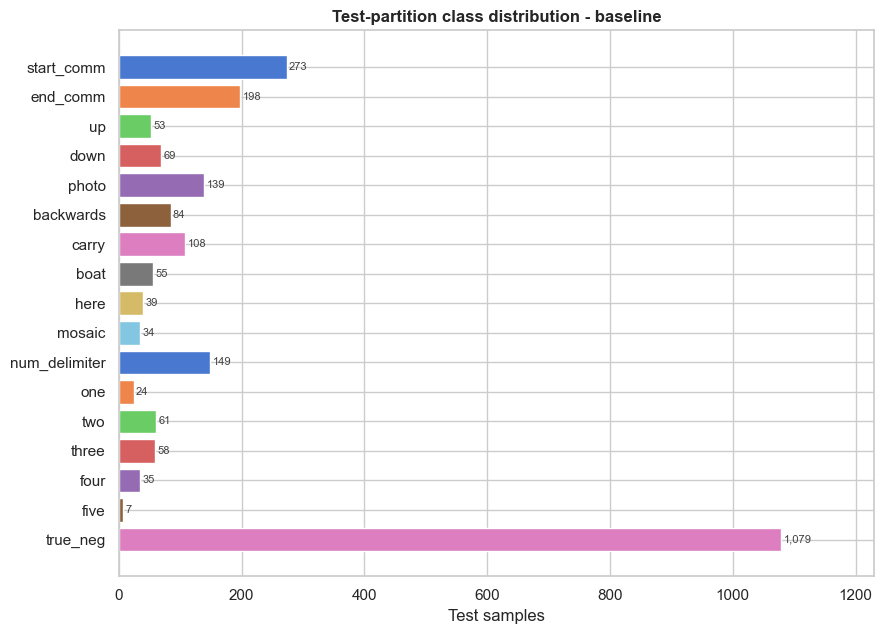

classes: 17  samples: 2,465
largest class  : true_neg (n=1079)
smallest class : five (n=7)
classes with fewer than 20 samples: 1


In [6]:
bundle = json.loads((EVAL_DIR / 'metrics.json').read_text(encoding='utf-8'))
test_metrics = bundle['metrics']
provenance = bundle['provenance']
CLASS_NAMES = bundle['class_names']  # canonical order, as written by the evaluator
cm = np.load(EVAL_DIR / 'confusion_matrix.npy')
per_class = pd.read_csv(EVAL_DIR / 'per_class.csv')

assert cm.shape == (17, 17), cm.shape
assert int(cm.sum()) == provenance['n_samples'], 'matrix total does not match provenance'
assert int(per_class['support'].sum()) == provenance['n_samples'], 'supports do not sum to n'
assert abs(np.trace(cm) / cm.sum() - test_metrics['overall_accuracy']) < 1e-12

order = per_class.sort_values('class_id').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(order['class_name'], order['support'], color=sns.color_palette('muted', 17))
for bar, n in zip(bars, order['support']):
    ax.text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2, f'{int(n):,}',
            va='center', fontsize=8, color='0.25')
ax.invert_yaxis()
ax.set_xlabel('Test samples')
ax.set_xlim(0, order['support'].max() * 1.14)
ax.set_title('Test-partition class distribution - baseline', fontweight='bold')
plt.tight_layout()
plt.savefig(EVAL_DIR / 'test_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'classes: {len(order)}  samples: {int(order["support"].sum()):,}')
print(f'largest class  : {order.loc[order["support"].idxmax(), "class_name"]} '
      f'(n={int(order["support"].max())})')
print(f'smallest class : {order.loc[order["support"].idxmin(), "class_name"]} '
      f'(n={int(order["support"].min())})')
print(f'classes with fewer than 20 samples: {int((order["support"] < 20).sum())}')

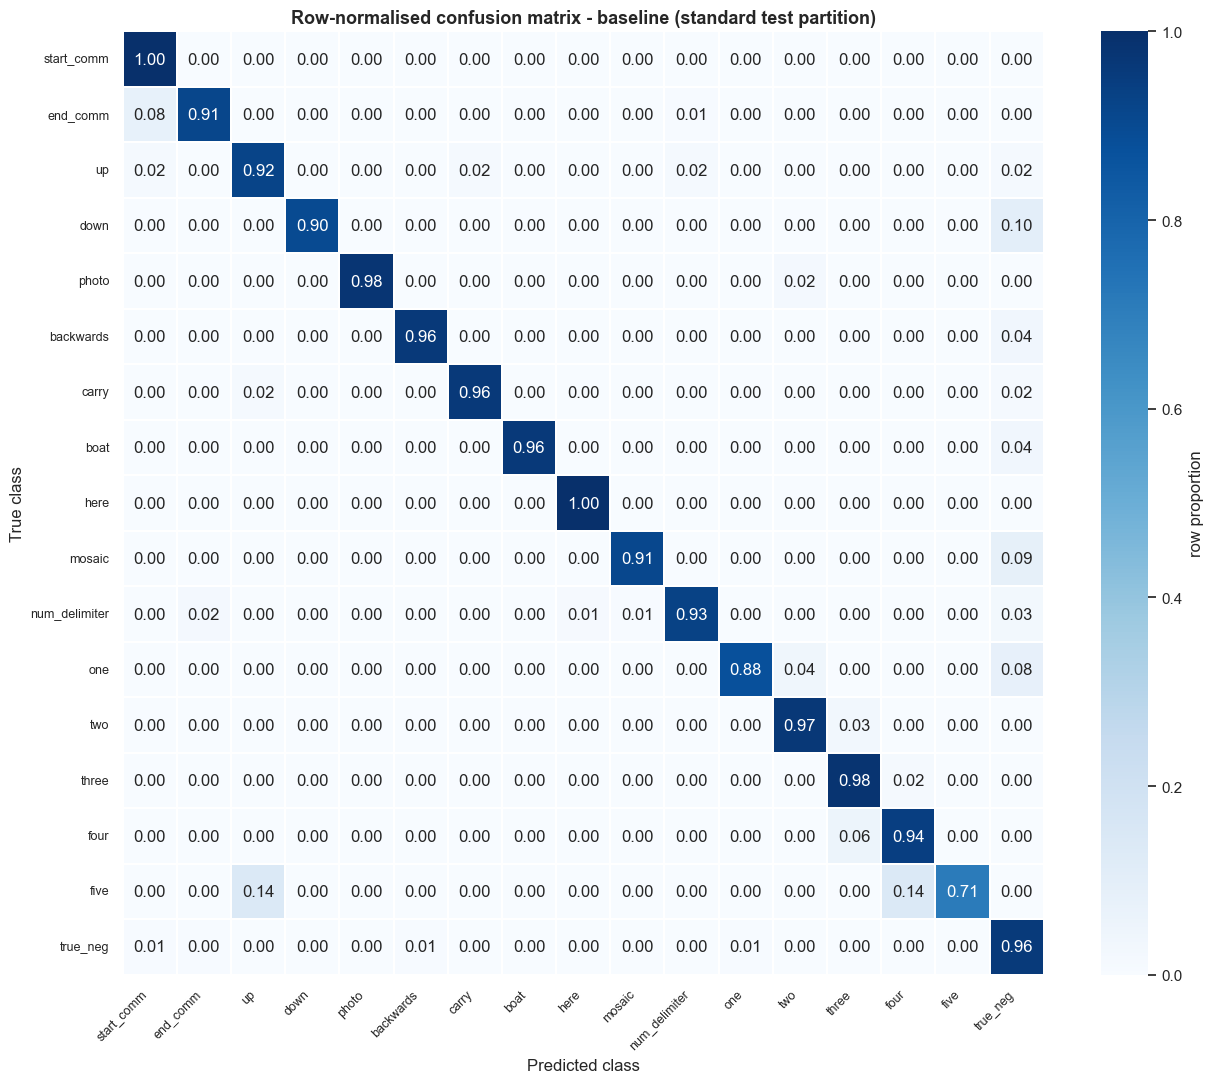

test accuracy   : 0.955781
test macro F1   : 0.932913
test min-class  : 0.714286
correct         : 2,356 / 2,465


In [7]:
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    ax=ax, linewidths=0.3, vmin=0.0, vmax=1.0,
    cbar_kws={'label': 'row proportion'},
)
ax.set_title(
    'Row-normalised confusion matrix - baseline (standard test partition)',
    fontsize=13, fontweight='bold',
)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

print(f'test accuracy   : {test_metrics["overall_accuracy"]:.6f}')
print(f'test macro F1   : {test_metrics["macro_f1"]:.6f}')
print(f'test min-class  : {test_metrics["min_class_accuracy"]:.6f}')
print(f'correct         : {int(np.trace(cm)):,} / {int(cm.sum()):,}')

## 5. Per-class metrics

Precision, recall, and F1 per class, with support. The predictions are reconstructed
from the stored confusion matrix, which is lossless for these quantities because the
matrix counts every (true, predicted) pair.

Every class is reported, including the classes with very small support. A high F1 on
a class with seven samples is not the same quantity as a high F1 on a class with a
thousand, and the support column is what makes the difference visible.

In [8]:
y_true, y_pred = [], []
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = int(cm[i, j])
        if count:
            y_true.extend([i] * count)
            y_pred.extend([j] * count)

print(
    classification_report(
        y_true, y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

               precision    recall  f1-score   support

   start_comm     0.9189    0.9963    0.9561       273
     end_comm     0.9577    0.9141    0.9354       198
           up     0.9245    0.9245    0.9245        53
         down     0.9688    0.8986    0.9323        69
        photo     0.9927    0.9784    0.9855       139
    backwards     0.9310    0.9643    0.9474        84
        carry     0.9541    0.9630    0.9585       108
         boat     0.9298    0.9636    0.9464        55
         here     0.9286    1.0000    0.9630        39
       mosaic     0.9688    0.9118    0.9394        34
num_delimiter     0.9586    0.9329    0.9456       149
          one     0.7500    0.8750    0.8077        24
          two     0.8939    0.9672    0.9291        61
        three     0.9344    0.9828    0.9580        58
         four     0.9167    0.9429    0.9296        35
         five     1.0000    0.7143    0.8333         7
     true_neg     0.9773    0.9583    0.9677      1079

     acc

In [9]:
per_class = per_class[['class_id', 'class_name', 'support', 'correct', 'accuracy', 'precision', 'recall', 'f1']]

print(f'support sums to {int(per_class["support"].sum()):,}')
print(f'correct sums to {int(per_class["correct"].sum()):,}')
print(f'classes present : {len(per_class)}')

per_class.round(4)

support sums to 2,465
correct sums to 2,356
classes present : 17


,class_id,class_name,support,correct,accuracy,precision,recall,f1
0,0,start_comm,273,272,0.9963,0.9189,0.9963,0.9561
1,1,end_comm,198,181,0.9141,0.9577,0.9141,0.9354
2,2,up,53,49,0.9245,0.9245,0.9245,0.9245
3,3,down,69,62,0.8986,0.9688,0.8986,0.9323
4,4,photo,139,136,0.9784,0.9927,0.9784,0.9855
5,5,backwards,84,81,0.9643,0.9310,0.9643,0.9474
6,6,carry,108,104,0.9630,0.9541,0.9630,0.9585
7,7,boat,55,53,0.9636,0.9298,0.9636,0.9464
8,8,here,39,39,1.0000,0.9286,1.0000,0.9630
9,9,mosaic,34,31,0.9118,0.9688,0.9118,0.9394


### Precision, recall, and F1 in one view

The same numbers as the table above, as a heat map. The colour scale is deliberately
truncated rather than spanning zero to one, because every value in this arm sits in a
narrow band and a full-range scale would render the whole table a single colour. The
printed value is authoritative; the colour is only there to make the pattern visible.

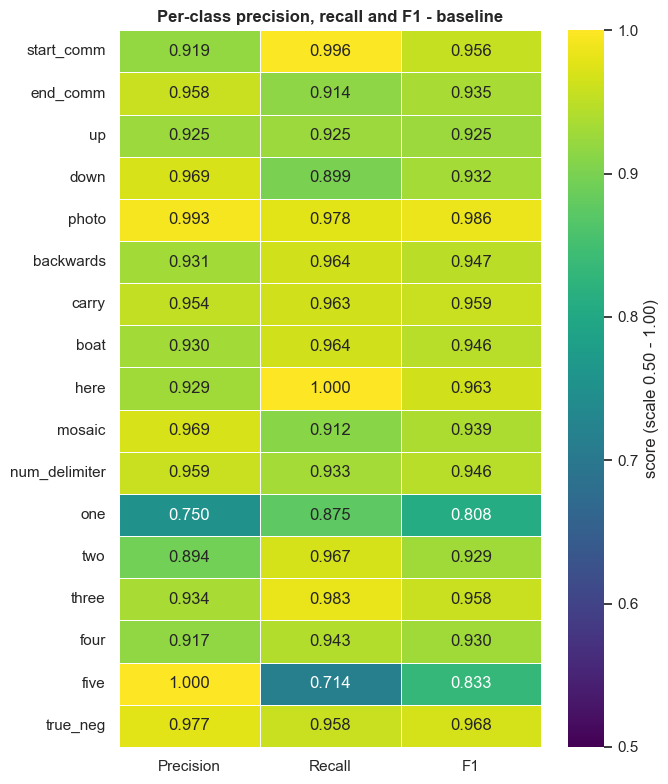

colour scale runs from 0.50 to 1.00; values below that are pinned to the floor
lowest value in the table: 0.7143


In [10]:
metric_cols = ['precision', 'recall', 'f1']
prf = order[metric_cols].to_numpy(dtype=float)
vmin = min(0.5, float(np.floor(prf.min() * 20) / 20))

fig, ax = plt.subplots(figsize=(6.8, 8))
sns.heatmap(
    prf, annot=True, fmt='.3f', cmap='viridis',
    vmin=vmin, vmax=1.0,
    xticklabels=['Precision', 'Recall', 'F1'],
    yticklabels=order['class_name'],
    ax=ax, linewidths=0.4,
    cbar_kws={'label': f'score (scale {vmin:.2f} - 1.00)'},
)
ax.set_title(
    'Per-class precision, recall and F1 - baseline',
    fontsize=12, fontweight='bold',
)
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(EVAL_DIR / 'per_class_prf_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'colour scale runs from {vmin:.2f} to 1.00; values below that are pinned to the floor')
print(f'lowest value in the table: {prf.min():.4f}')

### Most frequent confusions

The ten largest off-diagonal counts, with each count shown as a share of the true
class. The share matters more than the count: sixteen `end_comm` images read as
`start_comm` is eight per cent of that class, while the same count on a class of
seven would be the whole class.

Pairs whose share is large but whose class is tiny are marked, so that a visually
striking bar is not mistaken for the arm's main weakness.

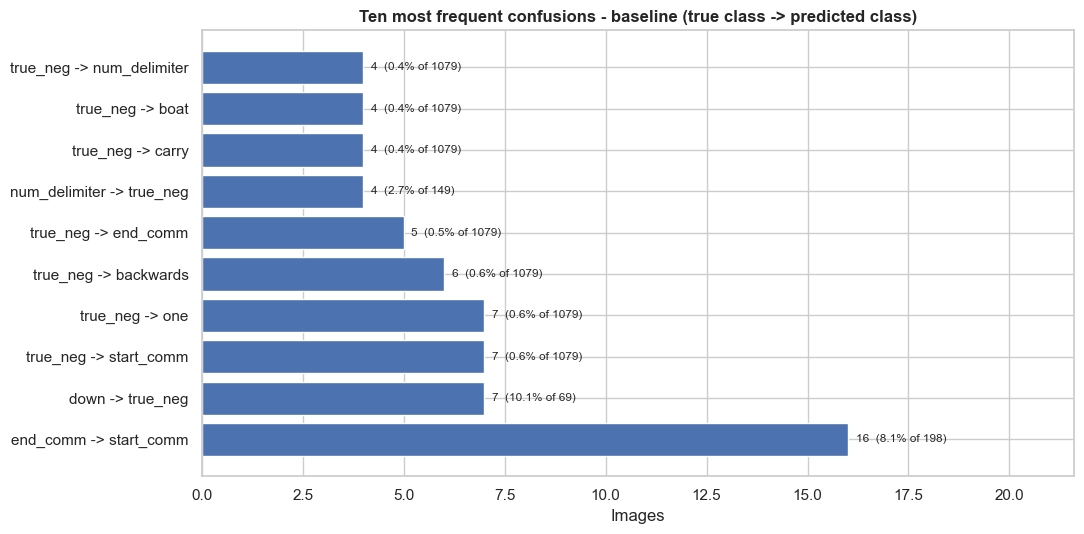

errors: 109 of 2,465 (4.42%)
these ten pairs account for 64 of them (58.7%)
red bars: true class has fewer than 20 test samples


In [11]:
off = cm.copy()
np.fill_diagonal(off, 0)
row_support = cm.sum(axis=1)

flat = np.argsort(off.ravel())[::-1]
pairs = []
for idx in flat:
    i, j = np.unravel_index(idx, cm.shape)
    count = int(cm[i, j])
    if count == 0:
        break
    pairs.append((CLASS_NAMES[i], CLASS_NAMES[j], count, count / row_support[i], int(row_support[i])))
    if len(pairs) == 10:
        break

pairs = pairs[::-1]  # largest at the top of the chart
labels = [f'{t} -> {p}' for t, p, _, _, _ in pairs]
counts = [c for _, _, c, _, _ in pairs]
shares = [s for _, _, _, s, _ in pairs]
supports = [n for _, _, _, _, n in pairs]
colours = ['#c44e52' if n < 20 else '#4c72b0' for n in supports]

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(labels, counts, color=colours)
for bar, c, s, n in zip(bars, counts, shares, supports):
    ax.text(bar.get_width() + max(counts) * 0.012, bar.get_y() + bar.get_height() / 2,
            f'{c}  ({s * 100:.1f}% of {n})', va='center', fontsize=8.5)
ax.set_xlabel('Images')
ax.set_xlim(0, max(counts) * 1.35)
ax.set_title(
    'Ten most frequent confusions - baseline (true class -> predicted class)',
    fontsize=12, fontweight='bold',
)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(EVAL_DIR / 'top_misclassifications.png', dpi=150, bbox_inches='tight')
plt.show()

total_errors = int(off.sum())
print(f'errors: {total_errors:,} of {int(cm.sum()):,} ({total_errors / cm.sum() * 100:.2f}%)')
print(f'these ten pairs account for {sum(counts):,} of them ({sum(counts) / total_errors * 100:.1f}%)')
print('red bars: true class has fewer than 20 test samples')

## 6. Per-class F1 chart

F1 by class, with the support of each class printed above its bar. The lowest bars
are not necessarily the classes with the most room for improvement; they may simply
be the classes with the least evidence.

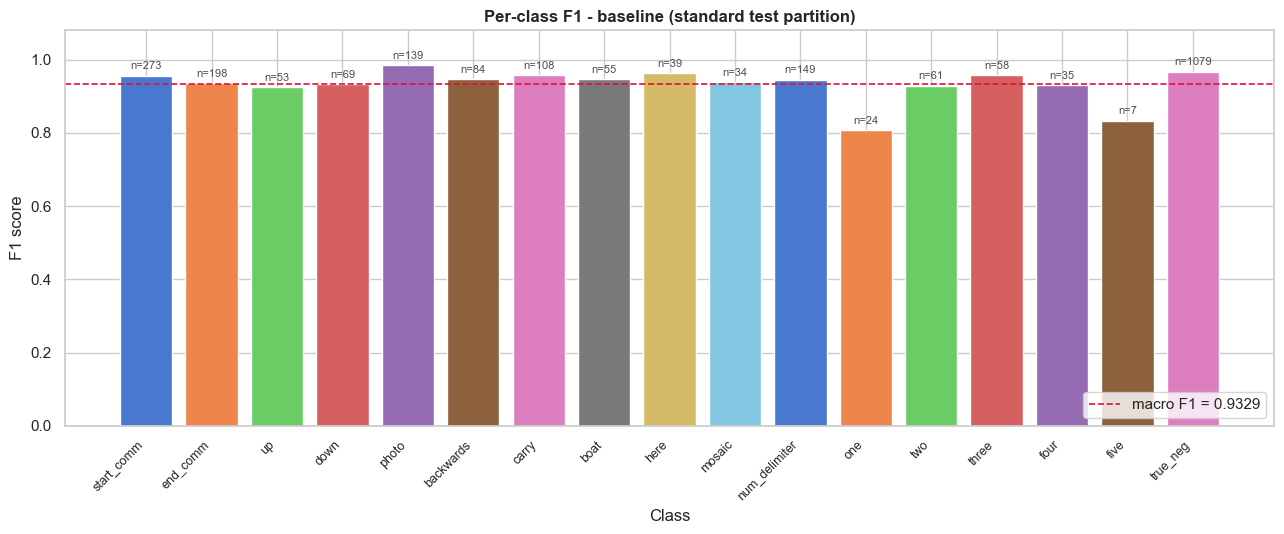

lowest F1        : one (0.8077, n=24)
lowest accuracy  : five (0.7143, n=7)


In [12]:
colors = sns.color_palette('muted', n_colors=len(order))

fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(order['class_name'], order['f1'], color=colors)

for bar, support in zip(bars, order['support']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.012,
        f'n={int(support)}',
        ha='center', va='bottom', fontsize=8, color='0.3',
    )

ax.set_ylim(0, 1.08)
ax.set_ylabel('F1 score')
ax.set_xlabel('Class')
ax.set_title('Per-class F1 - baseline (standard test partition)', fontweight='bold')
ax.axhline(test_metrics['macro_f1'], color='crimson', linestyle='--', linewidth=1.2,
           label=f'macro F1 = {test_metrics["macro_f1"]:.4f}')
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(EVAL_DIR / 'per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

worst = order.loc[order['f1'].idxmin()]
binding = order.loc[order['accuracy'].idxmin()]
print(f'lowest F1        : {worst["class_name"]} ({worst["f1"]:.4f}, n={int(worst["support"])})')
print(f'lowest accuracy  : {binding["class_name"]} ({binding["accuracy"]:.4f}, n={int(binding["support"])})')

## 7. Summary

What this notebook establishes, and what it does not.

In [13]:
lines = [
    f'Single-image ResNet-18 baseline: {provenance["parameters"]:,} parameters, seed {seed}.',
    f'Validation macro F1 at the selected epoch ({selected_epoch}): {selected["val_macro_f1"]:.6f}.',
    f'Test macro F1: {test_metrics["macro_f1"]:.6f}; test accuracy: {test_metrics["overall_accuracy"]:.6f}.',
    f'Test minimum class accuracy: {test_metrics["min_class_accuracy"]:.6f}, attained on "{binding["class_name"]}" with n={int(binding["support"])}.',
    f'The lowest per-class F1 is "{worst["class_name"]}" at {worst["f1"]:.4f}, with n={int(worst["support"])}.',
    f'{total_errors:,} of {int(cm.sum()):,} test images are misclassified, and the ten largest pairs cover {sum(counts) / total_errors * 100:.1f}% of them.',
    '',
    'Reading note: the minimum-class figure is a minimum over seventeen class accuracies, and',
    'the class that attains it may hold very few samples. One prediction moves it',
    'substantially, so it is reported with its support and is not used as a basis for a claim',
    'on its own.',
    '',
'This notebook measures the baseline. Whether it differs from the proposed model by more',
    'than single-seed variability is decided in the comparison notebook and in the results',
    'record, not here.',
]
print('\n'.join(lines))

Single-image ResNet-18 baseline: 11,185,233 parameters, seed 42.
Validation macro F1 at the selected epoch (19): 0.942009.
Test macro F1: 0.932913; test accuracy: 0.955781.
Test minimum class accuracy: 0.714286, attained on "five" with n=7.
The lowest per-class F1 is "one" at 0.8077, with n=24.
109 of 2,465 test images are misclassified, and the ten largest pairs cover 58.7% of them.

Reading note: the minimum-class figure is a minimum over seventeen class accuracies, and
the class that attains it may hold very few samples. One prediction moves it
substantially, so it is reported with its support and is not used as a basis for a claim
on its own.

This notebook measures the baseline. Whether it differs from the proposed model by more
than single-seed variability is decided in the comparison notebook and in the results
record, not here.


---

**Artefacts written by this notebook**

| File | Content |
|---|---|
| `training_curves.png` | Loss, accuracy, macro F1, and minimum class accuracy against epoch |
| `checkpoint_selection.png` | Selection rule applied to the validation record |
| `test_class_distribution.png` | Composition of the test partition by class |
| `per_class_prf_heatmap.png` | Precision, recall, and F1 per class |
| `top_misclassifications.png` | Ten largest confusion pairs, with share of the true class |
| `per_class_f1.png` | Per-class F1 with support annotated |

The confusion matrix and the machine-readable metrics are written by the evaluation
step, not by this notebook.